In [ ]:
# ============================================================
# MobileViT-S: STEPS 1–5 IN ONE CELL
#
# STEP 1: Install, imports, configuration
# STEP 2: Dataset count and fixed split
# STEP 3: Preprocessing, Dataset, DataLoader
# STEP 4: Build MobileViT-S model
# STEP 5: Training and evaluation functions
# ============================================================


# ============================================================
# STEP 1: INSTALL, DRIVE MOUNT, IMPORTS, CONFIGURATION
# ============================================================

!pip -q install -U timm fvcore openpyxl statsmodels

from google.colab import drive
drive.mount(
    "/content/drive"
)


# ------------------------------------------------------------
# Standard imports
# ------------------------------------------------------------

import os
import gc
import time
import random
import warnings

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

from tqdm.auto import tqdm


# ------------------------------------------------------------
# PyTorch imports
# ------------------------------------------------------------

import torch
import torch.nn as nn

from torch.utils.data import (
    Dataset,
    DataLoader
)

from torchvision import transforms

from torchvision.transforms import (
    InterpolationMode
)

import timm


# ------------------------------------------------------------
# Scikit-learn imports
# ------------------------------------------------------------

from sklearn.model_selection import (
    StratifiedKFold,
    train_test_split
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)


warnings.filterwarnings(
    "ignore"
)


# ============================================================
# EXPERIMENTAL CONFIGURATION
# Same settings used for EfficientNetB0
# ============================================================

SEED = 42

IMG_SIZE = 224

BATCH_SIZE = 32

EPOCHS = 30

LEARNING_RATE = 1e-4

N_FOLDS = 5

THRESHOLD = 0.50


# Google Drive-mounted images-এর জন্য stable value.
# এটি model training configuration পরিবর্তন করে না।

NUM_WORKERS = 0


# ============================================================
# MODEL INFORMATION
# ============================================================

MODEL_NAME = "MobileViT-S"

TIMM_MODEL_NAME = (
    "mobilevit_s.cvnets_in1k"
)


# ============================================================
# DATASET PATH
# ============================================================

DATASET_DIR = Path(
    "/content/drive/MyDrive/Brishty_ml/"
    "sevd_final/images"
)


# ============================================================
# OUTPUT PATH
# ============================================================

OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Brishty_ml/"
    "reviewer_final_results"
)


MODEL_OUTPUT_DIR = (
    OUTPUT_DIR /
    "02_MobileViT_S"
)

MODEL_DIR = (
    MODEL_OUTPUT_DIR /
    "saved_models"
)

HISTORY_DIR = (
    MODEL_OUTPUT_DIR /
    "training_history"
)

FIGURE_DIR = (
    MODEL_OUTPUT_DIR /
    "figures"
)

PREDICTION_DIR = (
    MODEL_OUTPUT_DIR /
    "predictions"
)

METRIC_DIR = (
    MODEL_OUTPUT_DIR /
    "metrics"
)


for folder in [
    OUTPUT_DIR,
    MODEL_OUTPUT_DIR,
    MODEL_DIR,
    HISTORY_DIR,
    FIGURE_DIR,
    PREDICTION_DIR,
    METRIC_DIR
]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# CLASS INFORMATION
# Same mapping used for EfficientNetB0
# ============================================================

CLASS_NAMES = [
    "encroachment_present",
    "no_encroachment"
]

CLASS_TO_IDX = {
    "encroachment_present": 0,
    "no_encroachment": 1
}

IMAGE_EXTENSIONS = (
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
)


# ============================================================
# DEVICE
# ============================================================

DEVICE = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


# ============================================================
# REPRODUCIBILITY
# ============================================================

def set_seed(seed=42):

    os.environ[
        "PYTHONHASHSEED"
    ] = str(seed)

    random.seed(
        seed
    )

    np.random.seed(
        seed
    )

    torch.manual_seed(
        seed
    )

    torch.cuda.manual_seed_all(
        seed
    )

    torch.backends.cudnn.deterministic = True

    torch.backends.cudnn.benchmark = False


set_seed(
    SEED
)


# ============================================================
# INITIAL CONFIGURATION CHECK
# ============================================================

print("=" * 75)
print("MobileViT-S EXPERIMENT CONFIGURATION")
print("=" * 75)

print(
    "Device:",
    DEVICE
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "GPU memory:",
        f"{torch.cuda.get_device_properties(0).total_memory / (1024 ** 3):.2f} GB"
    )

else:

    print(
        "GPU:",
        "Not available"
    )


print(
    "Dataset path:",
    DATASET_DIR
)

print(
    "Dataset folder exists:",
    DATASET_DIR.exists()
)

print(
    "Output path:",
    MODEL_OUTPUT_DIR
)

print(
    "Image size:",
    IMG_SIZE
)

print(
    "Batch size:",
    BATCH_SIZE
)

print(
    "Epochs:",
    EPOCHS
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Number of folds:",
    N_FOLDS
)

print(
    "Number of workers:",
    NUM_WORKERS
)


if not DATASET_DIR.exists():

    raise FileNotFoundError(
        f"Dataset directory was not found:\n"
        f"{DATASET_DIR}"
    )


for class_name in CLASS_NAMES:

    class_folder = (
        DATASET_DIR /
        class_name
    )

    print(
        f"{class_name} folder exists:",
        class_folder.exists()
    )

    if not class_folder.exists():

        raise FileNotFoundError(
            f"Class folder was not found:\n"
            f"{class_folder}"
        )


# ============================================================
# STEP 2: DATASET COUNT, TEST SPLIT, AND 5-FOLD ASSIGNMENT
# ============================================================

def collect_images(
    dataset_dir
):

    image_paths = []
    labels = []

    for class_name in CLASS_NAMES:

        class_folder = (
            dataset_dir /
            class_name
        )

        # Sorting directory paths as well as filenames
        # makes split regeneration reproducible.

        for root, directories, files in os.walk(
            class_folder
        ):

            directories.sort()

            for file_name in sorted(
                files
            ):

                if file_name.lower().endswith(
                    IMAGE_EXTENSIONS
                ):

                    image_path = str(
                        Path(root) /
                        file_name
                    )

                    image_paths.append(
                        image_path
                    )

                    labels.append(
                        CLASS_TO_IDX[
                            class_name
                        ]
                    )

    return (
        np.asarray(
            image_paths
        ),

        np.asarray(
            labels,
            dtype=np.int64
        )
    )


all_image_paths, all_labels = collect_images(
    DATASET_DIR
)


if len(all_image_paths) == 0:

    raise RuntimeError(
        f"No image was found inside:\n"
        f"{DATASET_DIR}"
    )


print(
    "\n" +
    "=" * 75
)

print(
    "CLEANED DATASET SUMMARY"
)

print(
    "=" * 75
)

print(
    "Total images found:",
    len(all_image_paths)
)


for class_name, class_index in (
    CLASS_TO_IDX.items()
):

    class_count = int(
        np.sum(
            all_labels ==
            class_index
        )
    )

    print(
        f"{class_name}: "
        f"{class_count} images"
    )


# ------------------------------------------------------------
# Create fixed 15% independent test set
# ------------------------------------------------------------

(
    development_paths,
    test_paths,
    development_labels,
    test_labels
) = train_test_split(

    all_image_paths,
    all_labels,

    test_size=0.15,

    random_state=SEED,

    stratify=all_labels,

    shuffle=True
)


# ------------------------------------------------------------
# Assign the development data to five fixed folds
# ------------------------------------------------------------

development_fold_ids = np.zeros(
    len(
        development_paths
    ),
    dtype=np.int64
)


stratified_kfold = StratifiedKFold(

    n_splits=N_FOLDS,

    shuffle=True,

    random_state=SEED
)


for fold_number, (
    _,
    validation_indices
) in enumerate(

    stratified_kfold.split(
        development_paths,
        development_labels
    ),

    start=1
):

    development_fold_ids[
        validation_indices
    ] = fold_number


if np.any(
    development_fold_ids == 0
):

    raise RuntimeError(
        "Some development samples were not assigned "
        "to a validation fold."
    )


# ------------------------------------------------------------
# Build split DataFrames
# ------------------------------------------------------------

development_df = pd.DataFrame({

    "image_path":
        development_paths,

    "label":
        development_labels.astype(
            int
        ),

    "class_name": [
        CLASS_NAMES[
            int(label)
        ]

        for label in
        development_labels
    ],

    "dataset_role":
        "development",

    "fold_id":
        development_fold_ids
})


test_df = pd.DataFrame({

    "image_path":
        test_paths,

    "label":
        test_labels.astype(
            int
        ),

    "class_name": [
        CLASS_NAMES[
            int(label)
        ]

        for label in
        test_labels
    ],

    "dataset_role":
        "test",

    "fold_id":
        0
})


complete_split_df = pd.concat(

    [
        development_df,
        test_df
    ],

    ignore_index=True
)


# ------------------------------------------------------------
# Save fixed split files
# ------------------------------------------------------------

COMPLETE_SPLIT_PATH = (
    OUTPUT_DIR /
    "fixed_test_and_5fold_split.csv"
)

FOLD_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_5fold_development_set.csv"
)

TEST_CSV_PATH = (
    OUTPUT_DIR /
    "fixed_test_set.csv"
)


complete_split_df.to_csv(
    COMPLETE_SPLIT_PATH,
    index=False
)

development_df.to_csv(
    FOLD_CSV_PATH,
    index=False
)

test_df.to_csv(
    TEST_CSV_PATH,
    index=False
)


print(
    "\nDevelopment images:",
    len(development_df)
)

print(
    "Independent test images:",
    len(test_df)
)


print(
    "\nDevelopment class distribution:"
)

print(
    development_df[
        "class_name"
    ].value_counts()
)


print(
    "\nIndependent test class distribution:"
)

print(
    test_df[
        "class_name"
    ].value_counts()
)


print(
    "\nFixed fold distribution:"
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    current_train_df = development_df[
        development_df[
            "fold_id"
        ] != fold_number
    ]

    current_validation_df = development_df[
        development_df[
            "fold_id"
        ] == fold_number
    ]

    print(
        f"\nFold {fold_number}:"
    )

    print(
        "  Training images:",
        len(
            current_train_df
        )
    )

    print(
        "  Validation images:",
        len(
            current_validation_df
        )
    )

    print(
        "  Validation distribution:"
    )

    print(
        current_validation_df[
            "class_name"
        ].value_counts()
    )


print(
    "\nSplit files saved:"
)

print(
    COMPLETE_SPLIT_PATH
)

print(
    FOLD_CSV_PATH
)

print(
    TEST_CSV_PATH
)


# ============================================================
# STEP 3: PREPROCESSING, DATASET CLASS, AND DATALOADER
# ============================================================

# MobileViT-S ImageNet checkpoint uses standard
# ImageNet mean and standard deviation.

IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


# ------------------------------------------------------------
# Training augmentation
# Same policy as EfficientNetB0:
# horizontal flip, rotation, zoom, and resize
# ------------------------------------------------------------

train_transform = transforms.Compose([

    transforms.Resize(
        (
            IMG_SIZE,
            IMG_SIZE
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.RandomHorizontalFlip(
        p=0.50
    ),

    # Keras RandomRotation(factor=0.1) corresponds
    # approximately to ±36 degrees.

    transforms.RandomRotation(
        degrees=36,
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.RandomAffine(
        degrees=0,
        scale=(
            0.90,
            1.10
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ------------------------------------------------------------
# Validation and test preprocessing
# ------------------------------------------------------------

evaluation_transform = transforms.Compose([

    transforms.Resize(
        (
            IMG_SIZE,
            IMG_SIZE
        ),
        interpolation=(
            InterpolationMode.BILINEAR
        )
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# ------------------------------------------------------------
# Custom Dataset
# ------------------------------------------------------------

class SEVDDataset(
    Dataset
):

    def __init__(
        self,
        dataframe,
        transform=None
    ):

        self.dataframe = (
            dataframe
            .reset_index(
                drop=True
            )
            .copy()
        )

        self.transform = transform


    def __len__(
        self
    ):

        return len(
            self.dataframe
        )


    def __getitem__(
        self,
        index
    ):

        row = self.dataframe.iloc[
            index
        ]

        image_path = str(
            row[
                "image_path"
            ]
        )

        label = float(
            row[
                "label"
            ]
        )


        try:

            with Image.open(
                image_path
            ) as opened_image:

                image = opened_image.convert(
                    "RGB"
                )

        except Exception as error:

            raise RuntimeError(
                f"Unable to load image:\n"
                f"{image_path}"
            ) from error


        if self.transform is not None:

            image = self.transform(
                image
            )


        return {

            "image":
                image,

            "label":
                torch.tensor(
                    label,
                    dtype=torch.float32
                ),

            "image_path":
                image_path
        }


# ------------------------------------------------------------
# DataLoader creator
# ------------------------------------------------------------

def create_dataloader(
    dataframe,
    transform,
    shuffle,
    fold_seed=SEED
):

    dataset = SEVDDataset(
        dataframe=dataframe,
        transform=transform
    )


    generator = torch.Generator()

    generator.manual_seed(
        fold_seed
    )


    dataloader = DataLoader(

        dataset,

        batch_size=BATCH_SIZE,

        shuffle=shuffle,

        num_workers=NUM_WORKERS,

        pin_memory=torch.cuda.is_available(),

        persistent_workers=False,

        drop_last=False,

        generator=(
            generator
            if shuffle
            else None
        )
    )


    return (
        dataset,
        dataloader
    )


# ------------------------------------------------------------
# Fixed independent test DataLoader
# ------------------------------------------------------------

test_dataset, test_loader = (
    create_dataloader(

        dataframe=test_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=SEED
    )
)


# ------------------------------------------------------------
# Fold 1 pipeline check
# ------------------------------------------------------------

CHECK_FOLD = 1


check_train_df = development_df[
    development_df[
        "fold_id"
    ] != CHECK_FOLD
].reset_index(
    drop=True
)


check_validation_df = development_df[
    development_df[
        "fold_id"
    ] == CHECK_FOLD
].reset_index(
    drop=True
)


(
    check_train_dataset,
    check_train_loader
) = create_dataloader(

    dataframe=check_train_df,

    transform=train_transform,

    shuffle=True,

    fold_seed=(
        SEED +
        CHECK_FOLD
    )
)


(
    check_validation_dataset,
    check_validation_loader
) = create_dataloader(

    dataframe=check_validation_df,

    transform=evaluation_transform,

    shuffle=False,

    fold_seed=(
        SEED +
        CHECK_FOLD
    )
)


sample_batch = next(
    iter(
        check_train_loader
    )
)


print(
    "\n" +
    "=" * 75
)

print(
    "DATALOADER CHECK"
)

print(
    "=" * 75
)

print(
    "Training images:",
    len(
        check_train_dataset
    )
)

print(
    "Validation images:",
    len(
        check_validation_dataset
    )
)

print(
    "Test images:",
    len(
        test_dataset
    )
)

print(
    "Image batch shape:",
    sample_batch[
        "image"
    ].shape
)

print(
    "Label batch shape:",
    sample_batch[
        "label"
    ].shape
)

print(
    "Training batches:",
    len(
        check_train_loader
    )
)

print(
    "Validation batches:",
    len(
        check_validation_loader
    )
)

print(
    "Test batches:",
    len(
        test_loader
    )
)


assert sample_batch[
    "image"
].shape[
    1:
] == (
    3,
    IMG_SIZE,
    IMG_SIZE
), (
    "Unexpected image batch shape."
)


# ============================================================
# STEP 4: BUILD MobileViT-S MODEL
# ============================================================

class MobileViTSBinaryClassifier(
    nn.Module
):

    def __init__(
        self,
        dropout_rate=0.4
    ):

        super().__init__()


        # ImageNet-pretrained MobileViT-S backbone

        self.backbone = timm.create_model(

            TIMM_MODEL_NAME,

            pretrained=True,

            num_classes=0,

            global_pool="avg"
        )


        # Freeze complete backbone
        # Same transfer-learning policy as EfficientNetB0

        for parameter in (
            self.backbone.parameters()
        ):

            parameter.requires_grad = False


        self.feature_dimension = (
            self.backbone.num_features
        )


        self.dropout = nn.Dropout(
            p=dropout_rate
        )


        self.binary_output = nn.Linear(
            self.feature_dimension,
            1
        )


    def forward(
        self,
        images
    ):

        features = self.backbone(
            images
        )

        features = self.dropout(
            features
        )

        logits = self.binary_output(
            features
        )

        return logits.squeeze(
            dim=1
        )


def build_mobilevit_s_model():

    model = MobileViTSBinaryClassifier(
        dropout_rate=0.4
    ).to(
        DEVICE
    )


    criterion = (
        nn.BCEWithLogitsLoss()
    )


    optimizer = torch.optim.Adam(

        filter(
            lambda parameter:
                parameter.requires_grad,

            model.parameters()
        ),

        lr=LEARNING_RATE
    )


    return (
        model,
        criterion,
        optimizer
    )


# ------------------------------------------------------------
# Build temporary model for verification
# ------------------------------------------------------------

verification_model, criterion, optimizer = (
    build_mobilevit_s_model()
)


total_parameters = sum(
    parameter.numel()
    for parameter in
    verification_model.parameters()
)


trainable_parameters = sum(
    parameter.numel()
    for parameter in
    verification_model.parameters()
    if parameter.requires_grad
)


frozen_parameters = (
    total_parameters -
    trainable_parameters
)


backbone_trainable_parameters = sum(
    parameter.numel()
    for parameter in
    verification_model.backbone.parameters()
    if parameter.requires_grad
)


verification_model.eval()


with torch.no_grad():

    dummy_input = torch.zeros(

        (
            2,
            3,
            IMG_SIZE,
            IMG_SIZE
        ),

        dtype=torch.float32,

        device=DEVICE
    )


    dummy_output = verification_model(
        dummy_input
    )


print(
    "\n" +
    "=" * 75
)

print(
    "MobileViT-S MODEL CONFIGURATION"
)

print(
    "=" * 75
)

print(
    "Model:",
    MODEL_NAME
)

print(
    "Pretrained checkpoint:",
    TIMM_MODEL_NAME
)

print(
    "Backbone trainable:",
    backbone_trainable_parameters > 0
)

print(
    "Dropout:",
    0.4
)

print(
    "Optimizer:",
    "Adam"
)

print(
    "Learning rate:",
    LEARNING_RATE
)

print(
    "Loss:",
    "BCEWithLogitsLoss"
)

print(
    "Total parameters:",
    f"{total_parameters:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_parameters:,}"
)

print(
    "Frozen parameters:",
    f"{frozen_parameters:,}"
)

print(
    "Dummy output shape:",
    dummy_output.shape
)


assert backbone_trainable_parameters == 0, (
    "The MobileViT-S backbone is not frozen."
)

assert dummy_output.shape == (
    2,
), (
    "Unexpected binary output shape."
)


del verification_model

gc.collect()

if torch.cuda.is_available():

    torch.cuda.empty_cache()


# ============================================================
# STEP 5: TRAINING AND EVALUATION FUNCTIONS
# ============================================================

def train_one_epoch(
    model,
    dataloader,
    criterion,
    optimizer,
    epoch_number
):

    model.train()

    # Frozen backbone remains in evaluation mode so that
    # BatchNorm statistics do not change.

    model.backbone.eval()


    total_loss = 0.0

    all_labels = []
    all_predictions = []


    progress_bar = tqdm(

        dataloader,

        desc=(
            f"Epoch {epoch_number:02d}/{EPOCHS} "
            f"Training"
        ),

        leave=False
    )


    for batch in progress_bar:

        images = batch[
            "image"
        ].to(
            DEVICE,
            non_blocking=True
        )


        labels = batch[
            "label"
        ].to(
            DEVICE,
            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        logits = model(
            images
        )


        loss = criterion(
            logits,
            labels
        )


        loss.backward()

        optimizer.step()


        probabilities = torch.sigmoid(
            logits
        )


        predictions = (
            probabilities >=
            THRESHOLD
        ).long()


        batch_size = images.size(
            0
        )


        total_loss += (
            loss.item() *
            batch_size
        )


        all_labels.extend(

            labels
            .detach()
            .cpu()
            .numpy()
            .astype(int)
            .tolist()
        )


        all_predictions.extend(

            predictions
            .detach()
            .cpu()
            .numpy()
            .astype(int)
            .tolist()
        )


        progress_bar.set_postfix(

            batch_loss=(
                f"{loss.item():.4f}"
            )
        )


    epoch_loss = (
        total_loss /
        len(
            dataloader.dataset
        )
    )


    epoch_accuracy = accuracy_score(
        all_labels,
        all_predictions
    )


    return {

        "loss":
            float(
                epoch_loss
            ),

        "accuracy":
            float(
                epoch_accuracy
            )
    }


def evaluate_model(
    model,
    dataloader,
    criterion,
    description="Validation"
):

    model.eval()


    total_loss = 0.0

    all_labels = []

    all_probabilities = []

    all_predictions = []

    all_image_paths = []


    progress_bar = tqdm(

        dataloader,

        desc=description,

        leave=False
    )


    with torch.no_grad():

        for batch in progress_bar:

            images = batch[
                "image"
            ].to(
                DEVICE,
                non_blocking=True
            )


            labels = batch[
                "label"
            ].to(
                DEVICE,
                non_blocking=True
            )


            logits = model(
                images
            )


            loss = criterion(
                logits,
                labels
            )


            probabilities = torch.sigmoid(
                logits
            )


            predictions = (
                probabilities >=
                THRESHOLD
            ).long()


            batch_size = images.size(
                0
            )


            total_loss += (
                loss.item() *
                batch_size
            )


            all_labels.extend(

                labels
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            all_probabilities.extend(

                probabilities
                .cpu()
                .numpy()
                .tolist()
            )


            all_predictions.extend(

                predictions
                .cpu()
                .numpy()
                .astype(int)
                .tolist()
            )


            all_image_paths.extend(
                batch[
                    "image_path"
                ]
            )


    labels_array = np.asarray(
        all_labels,
        dtype=int
    )


    probabilities_array = np.asarray(
        all_probabilities,
        dtype=float
    )


    predictions_array = np.asarray(
        all_predictions,
        dtype=int
    )


    average_loss = (
        total_loss /
        len(
            dataloader.dataset
        )
    )


    confusion = confusion_matrix(

        labels_array,

        predictions_array,

        labels=[
            0,
            1
        ]
    )


    return {

        "loss":
            float(
                average_loss
            ),

        "accuracy":
            float(
                accuracy_score(
                    labels_array,
                    predictions_array
                )
            ),

        "precision":
            float(
                precision_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "recall":
            float(
                recall_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "f1_score":
            float(
                f1_score(
                    labels_array,
                    predictions_array,
                    zero_division=0
                )
            ),

        "auc":
            float(
                roc_auc_score(
                    labels_array,
                    probabilities_array
                )
            ),

        "true_negative":
            int(
                confusion[
                    0,
                    0
                ]
            ),

        "false_positive":
            int(
                confusion[
                    0,
                    1
                ]
            ),

        "false_negative":
            int(
                confusion[
                    1,
                    0
                ]
            ),

        "true_positive":
            int(
                confusion[
                    1,
                    1
                ]
            ),

        "true_labels":
            labels_array,

        "probabilities":
            probabilities_array,

        "predictions":
            predictions_array,

        "image_paths":
            np.asarray(
                all_image_paths,
                dtype=str
            )
    }


print(
    "\n" +
    "=" * 75
)

print(
    "STEPS 1–5 COMPLETED SUCCESSFULLY"
)

print(
    "=" * 75
)

print(
    "Dataset split is ready."
)

print(
    "DataLoaders are ready."
)

print(
    "MobileViT-S model builder is ready."
)

print(
    "Training progress bars are enabled."
)

print(
    "No fold has been trained yet."
)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 1.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 65.9/65.9 kB 4.2 MB/s eta 0:00:00
Mounted at /content/drive
MobileViT-S EXPERIMENT CONFIGURATION
Device: cuda
GPU: Tesla T4
GPU memory: 14.56 GB
Dataset path: /content/drive/MyDrive/Brishty_ml/sevd_final/images
Dataset folder exists: True
Output path: /content/drive/MyDrive/Brishty_ml/reviewer_final_results/02_MobileViT_S
Image size: 224
Batch size: 32
Epochs: 30
Learning rate: 0.0001
Number of folds: 5
Number of workers: 0
encroachment_present folder exists: True
no_encroachment folder exists: True

CLEANED DATASET SUMMARY
Total images found: 7411
encroachment_present: 3891 images
no_encroachment: 3520 images

Development images: 6299
Independent test images: 1112

Development class distribution:
class_n

model.safetensors: reconstructing file:   0%|          |  0.00B / 22.4MB            

model.safetensors: downloading bytes:           |  0.00B            


MobileViT-S MODEL CONFIGURATION
Model: MobileViT-S
Pretrained checkpoint: mobilevit_s.cvnets_in1k
Backbone trainable: False
Dropout: 0.4
Optimizer: Adam
Learning rate: 0.0001
Loss: BCEWithLogitsLoss
Total parameters: 4,938,273
Trainable parameters: 641
Frozen parameters: 4,937,632
Dummy output shape: torch.Size([2])

STEPS 1–5 COMPLETED SUCCESSFULLY
Dataset split is ready.
DataLoaders are ready.
MobileViT-S model builder is ready.
Training progress bars are enabled.
No fold has been trained yet.



STARTING MobileViT-S FOLD 1/5
Training images: 5039
Validation images: 1260
Independent test images: 1112

Training class distribution:
class_name
encroachment_present    2646
no_encroachment         2393
Name: count, dtype: int64

Validation class distribution:
class_name
encroachment_present    661
no_encroachment         599
Name: count, dtype: int64


Epoch 01/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 01/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 1 | Epoch 01/30 - loss: 14.9992 - accuracy: 0.5007 - val_loss: 1.9482 - val_accuracy: 0.7159


Epoch 02/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

...

Epoch 30/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 30/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 1 | Epoch 30/30 - loss: 0.4808 - accuracy: 0.7678 - val_loss: 0.3756 - val_accuracy: 0.8325

Fold 1 training time: 130.00 minutes


Fold 1 Final Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 1 Independent Test:   0%|          | 0/35 [00:00<?, ?it/s]

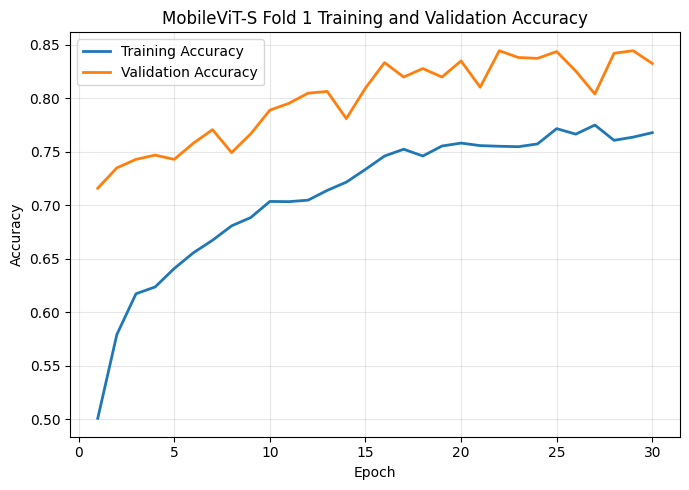

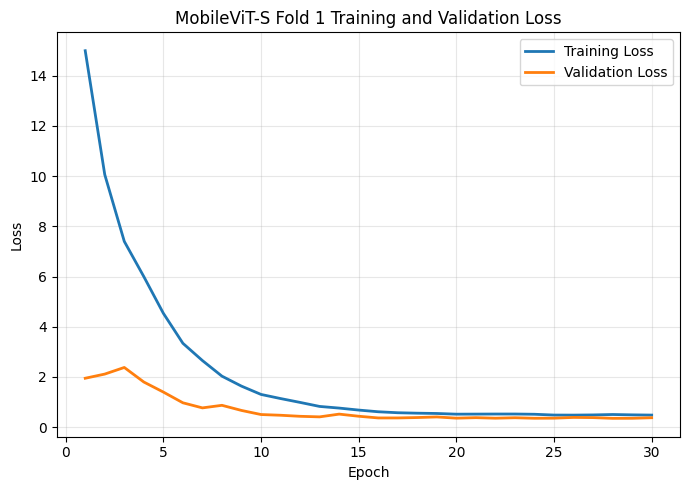


Validation result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
0,MobileViT-S,1,validation,0.375608,0.83254,0.784457,0.893155,0.835285,0.922013,514,147,64,535,7799.86883,129.997814



Independent test result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
1,MobileViT-S,1,test,0.380348,0.846223,0.806175,0.890152,0.846085,0.921891,471,113,58,470,7799.86883,129.997814



Saved checkpoint:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/02_MobileViT_S/saved_models/MobileViT-S_fold_1.pth

Saved history:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/02_MobileViT_S/training_history/MobileViT-S_fold_1_history.csv

Saved validation predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/02_MobileViT_S/predictions/MobileViT-S_fold_1_validation_predictions.csv

Saved test predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/02_MobileViT_S/predictions/MobileViT-S_fold_1_test_predictions.csv

Saved fold summary:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/02_MobileViT_S/metrics/MobileViT-S_fold_1_summary.csv

MobileViT-S FOLD 1 COMPLETED

STARTING MobileViT-S FOLD 2/5
Training images: 5039
Validation images: 1260
Independent test images: 1112

Training class distribution:
class_name
encroachment_present    2646
no_encroachment         2393
Name: count, dtype: int64

Validation class distribution:
c

...

Epoch 30/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 30/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 2 | Epoch 30/30 - loss: 0.4783 - accuracy: 0.7777 - val_loss: 0.3423 - val_accuracy: 0.8532

Fold 2 training time: 90.57 minutes


Fold 2 Final Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 2 Independent Test:   0%|          | 0/35 [00:00<?, ?it/s]

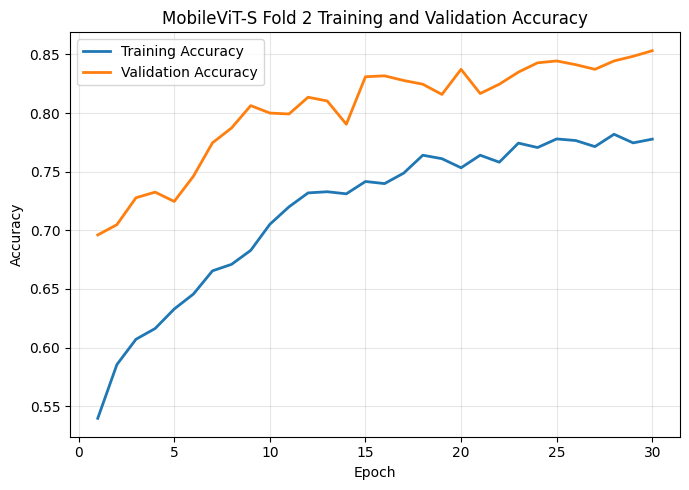

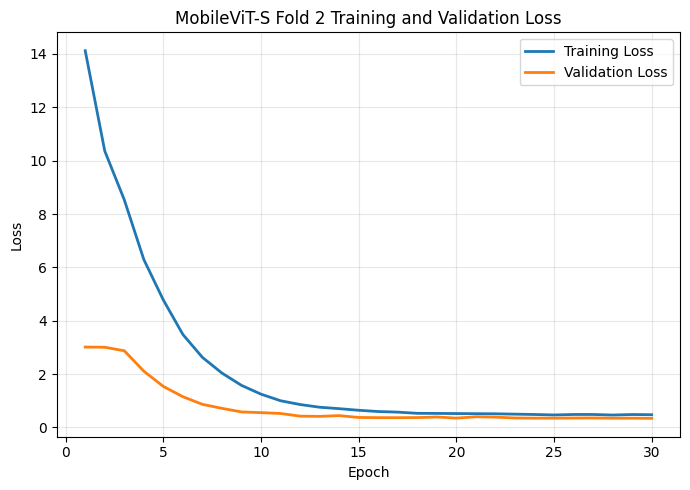


Validation result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
0,MobileViT-S,2,validation,0.342259,0.853175,0.869643,0.813022,0.84038,0.9298,588,73,112,487,5434.442421,90.57404



Independent test result:


,model,fold,dataset,loss,accuracy,precision,recall,f1_score,auc,true_negative,false_positive,false_negative,true_positive,training_time_seconds,training_time_minutes
1,MobileViT-S,2,test,0.336099,0.857914,0.868526,0.825758,0.846602,0.936271,518,66,92,436,5434.442421,90.57404



Saved checkpoint:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/02_MobileViT_S/saved_models/MobileViT-S_fold_2.pth

Saved history:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/02_MobileViT_S/training_history/MobileViT-S_fold_2_history.csv

Saved validation predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/02_MobileViT_S/predictions/MobileViT-S_fold_2_validation_predictions.csv

Saved test predictions:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/02_MobileViT_S/predictions/MobileViT-S_fold_2_test_predictions.csv

Saved fold summary:
/content/drive/MyDrive/Brishty_ml/reviewer_final_results/02_MobileViT_S/metrics/MobileViT-S_fold_2_summary.csv

MobileViT-S FOLD 2 COMPLETED

STARTING MobileViT-S FOLD 3/5
Training images: 5039
Validation images: 1260
Independent test images: 1112

Training class distribution:
class_name
encroachment_present    2645
no_encroachment         2394
Name: count, dtype: int64

Validation class distribution:
c

...

Fold 3 | Epoch 05/30 - loss: 5.8070 - accuracy: 0.6325 - val_loss: 1.8568 - val_accuracy: 0.7405


Epoch 06/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

Epoch 06/30 Validation:   0%|          | 0/40 [00:00<?, ?it/s]

Fold 3 | Epoch 06/30 - loss: 4.6658 - accuracy: 0.6424 - val_loss: 1.5352 - val_accuracy: 0.7040


Epoch 07/30 Training:   0%|          | 0/158 [00:00<?, ?it/s]

In [ ]:
# ============================================================
# CELLS 6–10 COMBINED:
# TRAIN AND EVALUATE MobileViT-S FOLDS 1–5
# ============================================================


# ============================================================
# 1. HELPER: SAVE TRAINING HISTORY AND GRAPHS
# ============================================================

def save_fold_history_and_graphs(
    history_dictionary,
    fold_number
):

    history_df = pd.DataFrame(
        history_dictionary
    )

    history_df.insert(
        0,
        "epoch",
        np.arange(
            1,
            len(history_df) + 1
        )
    )


    # --------------------------------------------------------
    # Save history CSV
    # --------------------------------------------------------

    history_path = (
        HISTORY_DIR /
        f"MobileViT-S_fold_{fold_number}_history.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )


    # --------------------------------------------------------
    # Accuracy graph
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        history_df["epoch"],
        history_df["accuracy"],
        linewidth=2,
        label="Training Accuracy"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_accuracy"],
        linewidth=2,
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")

    plt.title(
        f"MobileViT-S Fold {fold_number} "
        f"Training and Validation Accuracy"
    )

    plt.legend()
    plt.grid(alpha=0.30)
    plt.tight_layout()


    accuracy_path = (
        FIGURE_DIR /
        f"MobileViT-S_fold_{fold_number}_accuracy.png"
    )

    plt.savefig(
        accuracy_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


    # --------------------------------------------------------
    # Loss graph
    # --------------------------------------------------------

    plt.figure(
        figsize=(7, 5)
    )

    plt.plot(
        history_df["epoch"],
        history_df["loss"],
        linewidth=2,
        label="Training Loss"
    )

    plt.plot(
        history_df["epoch"],
        history_df["val_loss"],
        linewidth=2,
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")

    plt.title(
        f"MobileViT-S Fold {fold_number} "
        f"Training and Validation Loss"
    )

    plt.legend()
    plt.grid(alpha=0.30)
    plt.tight_layout()


    loss_path = (
        FIGURE_DIR /
        f"MobileViT-S_fold_{fold_number}_loss.png"
    )

    plt.savefig(
        loss_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()


    return {
        "history_dataframe": history_df,
        "history_path": history_path,
        "accuracy_path": accuracy_path,
        "loss_path": loss_path
    }


# ============================================================
# 2. HELPER: SAVE PREDICTIONS
# ============================================================

def save_fold_predictions(
    evaluation_result,
    fold_number,
    dataset_name
):

    prediction_df = pd.DataFrame({

        "image_path":
            evaluation_result[
                "image_paths"
            ],

        "label":
            evaluation_result[
                "true_labels"
            ],

        "class_name": [
            CLASS_NAMES[int(label)]
            for label in
            evaluation_result[
                "true_labels"
            ]
        ],

        "predicted_probability_class_1":
            evaluation_result[
                "probabilities"
            ],

        "predicted_label":
            evaluation_result[
                "predictions"
            ],

        "predicted_class_name": [
            CLASS_NAMES[int(label)]
            for label in
            evaluation_result[
                "predictions"
            ]
        ]
    })


    prediction_df[
        "correct_prediction"
    ] = (
        prediction_df["label"] ==
        prediction_df["predicted_label"]
    )


    prediction_path = (
        PREDICTION_DIR /
        f"MobileViT-S_fold_{fold_number}_"
        f"{dataset_name}_predictions.csv"
    )


    prediction_df.to_csv(
        prediction_path,
        index=False
    )


    return (
        prediction_df,
        prediction_path
    )


# ============================================================
# 3. HELPER: SAVE MODEL CHECKPOINT
# ============================================================

def save_fold_checkpoint(
    model,
    fold_number
):

    checkpoint_path = (
        MODEL_DIR /
        f"MobileViT-S_fold_{fold_number}.pth"
    )


    checkpoint = {

        "model_name":
            MODEL_NAME,

        "timm_model_name":
            TIMM_MODEL_NAME,

        "fold":
            fold_number,

        "image_size":
            IMG_SIZE,

        "batch_size":
            BATCH_SIZE,

        "epochs":
            EPOCHS,

        "learning_rate":
            LEARNING_RATE,

        "threshold":
            THRESHOLD,

        "class_names":
            CLASS_NAMES,

        "class_to_idx":
            CLASS_TO_IDX,

        "model_state_dict":
            model.state_dict()
    }


    torch.save(
        checkpoint,
        checkpoint_path
    )


    return checkpoint_path


# ============================================================
# 4. HELPER: CREATE SUMMARY RECORD
# ============================================================

def create_summary_record(
    evaluation_result,
    fold_number,
    dataset_name,
    training_time_seconds
):

    return {

        "model":
            MODEL_NAME,

        "fold":
            int(fold_number),

        "dataset":
            dataset_name,

        "loss":
            evaluation_result["loss"],

        "accuracy":
            evaluation_result["accuracy"],

        "precision":
            evaluation_result["precision"],

        "recall":
            evaluation_result["recall"],

        "f1_score":
            evaluation_result["f1_score"],

        "auc":
            evaluation_result["auc"],

        "true_negative":
            evaluation_result["true_negative"],

        "false_positive":
            evaluation_result["false_positive"],

        "false_negative":
            evaluation_result["false_negative"],

        "true_positive":
            evaluation_result["true_positive"],

        "training_time_seconds":
            float(training_time_seconds),

        "training_time_minutes":
            float(
                training_time_seconds / 60
            )
    }


# ============================================================
# 5. TRAIN ALL FIVE FOLDS
# ============================================================

all_fold_summary_rows = []

completed_fold_results = {}


for fold_number in range(
    1,
    N_FOLDS + 1
):

    print(
        "\n" +
        "=" * 80
    )

    print(
        f"STARTING MobileViT-S FOLD "
        f"{fold_number}/{N_FOLDS}"
    )

    print(
        "=" * 80
    )


    # --------------------------------------------------------
    # Prepare fold DataFrames
    # --------------------------------------------------------

    fold_train_df = (
        development_df[
            development_df[
                "fold_id"
            ] != fold_number
        ]
        .reset_index(
            drop=True
        )
    )


    fold_validation_df = (
        development_df[
            development_df[
                "fold_id"
            ] == fold_number
        ]
        .reset_index(
            drop=True
        )
    )


    print(
        "Training images:",
        len(fold_train_df)
    )

    print(
        "Validation images:",
        len(fold_validation_df)
    )

    print(
        "Independent test images:",
        len(test_df)
    )


    print(
        "\nTraining class distribution:"
    )

    print(
        fold_train_df[
            "class_name"
        ].value_counts()
    )


    print(
        "\nValidation class distribution:"
    )

    print(
        fold_validation_df[
            "class_name"
        ].value_counts()
    )


    # --------------------------------------------------------
    # Create fresh DataLoaders
    # --------------------------------------------------------

    (
        fold_train_dataset,
        fold_train_loader
    ) = create_dataloader(

        dataframe=fold_train_df,

        transform=train_transform,

        shuffle=True,

        fold_seed=(
            SEED +
            fold_number
        )
    )


    (
        fold_validation_dataset,
        fold_validation_loader
    ) = create_dataloader(

        dataframe=fold_validation_df,

        transform=evaluation_transform,

        shuffle=False,

        fold_seed=(
            SEED +
            fold_number
        )
    )


    # --------------------------------------------------------
    # Reset random seed and GPU memory
    # --------------------------------------------------------

    set_seed(
        SEED +
        fold_number
    )


    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    # --------------------------------------------------------
    # Build a fresh pretrained model
    # --------------------------------------------------------
    # Every fold starts from the same ImageNet-pretrained
    # MobileViT-S weights.

    model, criterion, optimizer = (
        build_mobilevit_s_model()
    )


    # --------------------------------------------------------
    # Training history
    # --------------------------------------------------------

    history_dictionary = {

        "loss": [],

        "accuracy": [],

        "val_loss": [],

        "val_accuracy": []
    }


    # --------------------------------------------------------
    # Train 30 epochs
    # --------------------------------------------------------

    training_start_time = (
        time.perf_counter()
    )


    for epoch_number in range(
        1,
        EPOCHS + 1
    ):

        training_result = train_one_epoch(

            model=model,

            dataloader=fold_train_loader,

            criterion=criterion,

            optimizer=optimizer,

            epoch_number=epoch_number
        )


        validation_result = evaluate_model(

            model=model,

            dataloader=fold_validation_loader,

            criterion=criterion,

            description=(
                f"Epoch {epoch_number:02d}/{EPOCHS} "
                f"Validation"
            )
        )


        history_dictionary[
            "loss"
        ].append(
            training_result[
                "loss"
            ]
        )


        history_dictionary[
            "accuracy"
        ].append(
            training_result[
                "accuracy"
            ]
        )


        history_dictionary[
            "val_loss"
        ].append(
            validation_result[
                "loss"
            ]
        )


        history_dictionary[
            "val_accuracy"
        ].append(
            validation_result[
                "accuracy"
            ]
        )


        print(
            f"Fold {fold_number} | "
            f"Epoch {epoch_number:02d}/{EPOCHS} - "
            f"loss: {training_result['loss']:.4f} - "
            f"accuracy: {training_result['accuracy']:.4f} - "
            f"val_loss: {validation_result['loss']:.4f} - "
            f"val_accuracy: {validation_result['accuracy']:.4f}"
        )


    training_end_time = (
        time.perf_counter()
    )


    training_time_seconds = (
        training_end_time -
        training_start_time
    )


    training_time_minutes = (
        training_time_seconds /
        60
    )


    print(
        f"\nFold {fold_number} training time: "
        f"{training_time_minutes:.2f} minutes"
    )


    # --------------------------------------------------------
    # Final validation evaluation
    # --------------------------------------------------------

    final_validation_result = evaluate_model(

        model=model,

        dataloader=fold_validation_loader,

        criterion=criterion,

        description=(
            f"Fold {fold_number} Final Validation"
        )
    )


    # --------------------------------------------------------
    # Independent test evaluation
    # --------------------------------------------------------

    final_test_result = evaluate_model(

        model=model,

        dataloader=test_loader,

        criterion=criterion,

        description=(
            f"Fold {fold_number} Independent Test"
        )
    )


    # --------------------------------------------------------
    # Save history and graphs
    # --------------------------------------------------------

    history_outputs = (
        save_fold_history_and_graphs(

            history_dictionary=(
                history_dictionary
            ),

            fold_number=fold_number
        )
    )


    # --------------------------------------------------------
    # Save predictions
    # --------------------------------------------------------

    (
        validation_prediction_df,
        validation_prediction_path
    ) = save_fold_predictions(

        evaluation_result=(
            final_validation_result
        ),

        fold_number=fold_number,

        dataset_name="validation"
    )


    (
        test_prediction_df,
        test_prediction_path
    ) = save_fold_predictions(

        evaluation_result=(
            final_test_result
        ),

        fold_number=fold_number,

        dataset_name="test"
    )


    # --------------------------------------------------------
    # Save model checkpoint
    # --------------------------------------------------------

    checkpoint_path = (
        save_fold_checkpoint(

            model=model,

            fold_number=fold_number
        )
    )


    # --------------------------------------------------------
    # Create and save fold summary
    # --------------------------------------------------------

    validation_summary = (
        create_summary_record(

            evaluation_result=(
                final_validation_result
            ),

            fold_number=fold_number,

            dataset_name="validation",

            training_time_seconds=(
                training_time_seconds
            )
        )
    )


    test_summary = (
        create_summary_record(

            evaluation_result=(
                final_test_result
            ),

            fold_number=fold_number,

            dataset_name="test",

            training_time_seconds=(
                training_time_seconds
            )
        )
    )


    fold_summary_df = pd.DataFrame([

        validation_summary,

        test_summary
    ])


    fold_summary_path = (
        METRIC_DIR /
        f"MobileViT-S_fold_{fold_number}_summary.csv"
    )


    fold_summary_df.to_csv(
        fold_summary_path,
        index=False
    )


    all_fold_summary_rows.extend([

        validation_summary,

        test_summary
    ])


    # --------------------------------------------------------
    # Store current fold result in runtime
    # --------------------------------------------------------

    completed_fold_results[
        fold_number
    ] = {

        "history":
            history_outputs[
                "history_dataframe"
            ],

        "validation_result":
            final_validation_result,

        "test_result":
            final_test_result,

        "summary":
            fold_summary_df,

        "checkpoint_path":
            checkpoint_path,

        "training_time_seconds":
            training_time_seconds
    }


    # --------------------------------------------------------
    # Display fold result
    # --------------------------------------------------------

    print(
        "\nValidation result:"
    )

    display(
        fold_summary_df[
            fold_summary_df[
                "dataset"
            ] == "validation"
        ]
    )


    print(
        "\nIndependent test result:"
    )

    display(
        fold_summary_df[
            fold_summary_df[
                "dataset"
            ] == "test"
        ]
    )


    print(
        "\nSaved checkpoint:"
    )

    print(
        checkpoint_path
    )


    print(
        "\nSaved history:"
    )

    print(
        history_outputs[
            "history_path"
        ]
    )


    print(
        "\nSaved validation predictions:"
    )

    print(
        validation_prediction_path
    )


    print(
        "\nSaved test predictions:"
    )

    print(
        test_prediction_path
    )


    print(
        "\nSaved fold summary:"
    )

    print(
        fold_summary_path
    )


    print(
        "\n" +
        "=" * 80
    )

    print(
        f"MobileViT-S FOLD {fold_number} COMPLETED"
    )

    print(
        "=" * 80
    )


    # --------------------------------------------------------
    # Free memory before next fold
    # --------------------------------------------------------

    del model
    del criterion
    del optimizer

    del fold_train_loader
    del fold_validation_loader

    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ============================================================
# 6. SAVE COMPLETE FIVE-FOLD RAW SUMMARY
# ============================================================

all_folds_summary_df = pd.DataFrame(
    all_fold_summary_rows
)


all_folds_summary_path = (
    METRIC_DIR /
    "MobileViT-S_all_5fold_results.csv"
)


all_folds_summary_df.to_csv(
    all_folds_summary_path,
    index=False
)


# ============================================================
# 7. FINAL COMPLETION MESSAGE
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "MobileViT-S ALL FIVE FOLDS COMPLETED"
)

print(
    "=" * 80
)


print(
    "\nAll five-fold raw results:"
)

print(
    all_folds_summary_path
)


print(
    "\nValidation results:"
)

display(
    all_folds_summary_df[
        all_folds_summary_df[
            "dataset"
        ] == "validation"
    ]
)


print(
    "\nIndependent test results:"
)

display(
    all_folds_summary_df[
        all_folds_summary_df[
            "dataset"
        ] == "test"
    ]
)


print(
    "\nAll outputs were saved inside:"
)

print(
    MODEL_OUTPUT_DIR
)

In [ ]:
# ============================================================
# FINAL POST-TRAINING ANALYSIS
# MobileViT-S 5-Fold Cross-Validation
# Run only after all five folds are completed
# ============================================================

from pathlib import Path

import gc
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch

from scipy import stats

from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    confusion_matrix
)

warnings.filterwarnings("ignore")


# ============================================================
# 1. FINAL OUTPUT DIRECTORIES
# ============================================================

FINAL_RESULTS_DIR = (
    MODEL_OUTPUT_DIR /
    "final_standard_paper_results"
)

FINAL_TABLE_DIR = (
    FINAL_RESULTS_DIR /
    "tables"
)

FINAL_FIGURE_DIR = (
    FINAL_RESULTS_DIR /
    "figures"
)


FINAL_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FINAL_FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("=" * 80)
print("MobileViT-S FINAL POST-TRAINING ANALYSIS")
print("=" * 80)

print(
    "Final output directory:",
    FINAL_RESULTS_DIR
)


# ============================================================
# 2. FILE CHECK FUNCTION
# ============================================================

def verify_file(
    file_path
):

    file_path = Path(
        file_path
    )

    if not file_path.exists():

        raise FileNotFoundError(
            f"Required file was not found:\n"
            f"{file_path}"
        )

    return file_path


# ============================================================
# 3. VERIFY ALL REQUIRED FILES
# ============================================================

for fold_number in range(
    1,
    N_FOLDS + 1
):

    verify_file(
        METRIC_DIR /
        f"MobileViT-S_fold_{fold_number}_summary.csv"
    )

    verify_file(
        HISTORY_DIR /
        f"MobileViT-S_fold_{fold_number}_history.csv"
    )

    verify_file(
        PREDICTION_DIR /
        f"MobileViT-S_fold_{fold_number}_"
        f"validation_predictions.csv"
    )

    verify_file(
        MODEL_DIR /
        f"MobileViT-S_fold_{fold_number}.pth"
    )


verify_file(
    TEST_CSV_PATH
)


print(
    "All required fold files were found."
)


# ============================================================
# 4. READ FIVE-FOLD VALIDATION RESULTS
# ============================================================

validation_metric_rows = []


for fold_number in range(
    1,
    N_FOLDS + 1
):

    summary_path = (
        METRIC_DIR /
        f"MobileViT-S_fold_{fold_number}_summary.csv"
    )

    fold_summary_df = pd.read_csv(
        summary_path
    )

    validation_row = fold_summary_df[
        fold_summary_df[
            "dataset"
        ]
        .astype(str)
        .str.lower()
        .eq("validation")
    ]


    if len(
        validation_row
    ) != 1:

        raise ValueError(
            f"Fold {fold_number} must contain "
            f"exactly one validation result row."
        )


    validation_row = (
        validation_row
        .iloc[0]
        .to_dict()
    )

    validation_row[
        "fold"
    ] = fold_number

    validation_metric_rows.append(
        validation_row
    )


validation_metrics_df = pd.DataFrame(
    validation_metric_rows
)


validation_metrics_df = (
    validation_metrics_df
    .sort_values(
        "fold"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\nFive-fold validation results:"
)

display(
    validation_metrics_df[
        [
            "fold",
            "loss",
            "accuracy",
            "precision",
            "recall",
            "f1_score",
            "auc",
            "training_time_minutes"
        ]
    ]
)


# ============================================================
# 5. PERFORMANCE TABLE: MEAN ± STANDARD DEVIATION
# ============================================================

performance_metric_mapping = {

    "Loss":
        "loss",

    "Accuracy (%)":
        "accuracy",

    "Precision (%)":
        "precision",

    "Recall (%)":
        "recall",

    "F1-Score (%)":
        "f1_score",

    "AUC":
        "auc"
}


performance_record = {

    "Model":
        MODEL_NAME
}


for display_name, column_name in (
    performance_metric_mapping.items()
):

    values = (
        validation_metrics_df[
            column_name
        ]
        .astype(float)
        .values
    )


    if display_name in [

        "Accuracy (%)",
        "Precision (%)",
        "Recall (%)",
        "F1-Score (%)"
    ]:

        values = (
            values *
            100
        )


    mean_value = float(
        np.mean(
            values
        )
    )

    standard_deviation = float(
        np.std(
            values,
            ddof=1
        )
    )


    performance_record[
        display_name
    ] = (
        f"{mean_value:.2f} ± "
        f"{standard_deviation:.2f}"
    )


performance_table_df = pd.DataFrame([
    performance_record
])


performance_table_path = (
    FINAL_TABLE_DIR /
    "MobileViT-S_performance_mean_std.csv"
)


performance_table_df.to_csv(
    performance_table_path,
    index=False
)


print(
    "\nPerformance Mean ± SD:"
)

display(
    performance_table_df
)


# ============================================================
# 6. ACCURACY 95% CONFIDENCE INTERVAL
# ============================================================

accuracy_values = (
    validation_metrics_df[
        "accuracy"
    ]
    .astype(float)
    .values *
    100
)


mean_accuracy = float(
    np.mean(
        accuracy_values
    )
)


accuracy_standard_deviation = float(
    np.std(
        accuracy_values,
        ddof=1
    )
)


accuracy_standard_error = (
    accuracy_standard_deviation /
    np.sqrt(
        N_FOLDS
    )
)


t_critical = stats.t.ppf(
    0.975,
    df=N_FOLDS - 1
)


confidence_margin = (
    t_critical *
    accuracy_standard_error
)


confidence_lower = (
    mean_accuracy -
    confidence_margin
)


confidence_upper = (
    mean_accuracy +
    confidence_margin
)


confidence_interval_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Mean Accuracy (%)":
            mean_accuracy,

        "Standard Deviation (%)":
            accuracy_standard_deviation,

        "Standard Error (%)":
            accuracy_standard_error,

        "95% CI Lower (%)":
            confidence_lower,

        "95% CI Upper (%)":
            confidence_upper,

        "Paper Format":
            (
                f"{mean_accuracy:.2f}% "
                f"({confidence_lower:.2f}%–"
                f"{confidence_upper:.2f}%)"
            )
    }
])


confidence_interval_path = (
    FINAL_TABLE_DIR /
    "MobileViT-S_statistical_95CI.csv"
)


confidence_interval_df.to_csv(
    confidence_interval_path,
    index=False
)


print(
    "\nAccuracy 95% Confidence Interval:"
)

display(
    confidence_interval_df
)


# ============================================================
# 7. TRAINING TIME TABLE
# ============================================================

training_time_values = (
    validation_metrics_df[
        "training_time_minutes"
    ]
    .astype(float)
    .values
)


mean_training_time = float(
    np.mean(
        training_time_values
    )
)


training_time_standard_deviation = float(
    np.std(
        training_time_values,
        ddof=1
    )
)


training_time_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Mean Training Time (minutes)":
            mean_training_time,

        "Training Time SD (minutes)":
            training_time_standard_deviation,

        "Mean ± SD":
            (
                f"{mean_training_time:.2f} ± "
                f"{training_time_standard_deviation:.2f}"
            )
    }
])


training_time_path = (
    FINAL_TABLE_DIR /
    "MobileViT-S_training_time_mean_std.csv"
)


training_time_df.to_csv(
    training_time_path,
    index=False
)


print(
    "\nTraining Time Mean ± SD:"
)

display(
    training_time_df
)


# ============================================================
# 8. LOAD ALL FIVE TRAINING HISTORIES
# ============================================================

training_accuracy_list = []

validation_accuracy_list = []

training_loss_list = []

validation_loss_list = []


for fold_number in range(
    1,
    N_FOLDS + 1
):

    history_path = (
        HISTORY_DIR /
        f"MobileViT-S_fold_{fold_number}_history.csv"
    )

    history_df = pd.read_csv(
        history_path
    )


    required_history_columns = [

        "loss",
        "accuracy",
        "val_loss",
        "val_accuracy"
    ]


    for required_column in (
        required_history_columns
    ):

        if required_column not in (
            history_df.columns
        ):

            raise KeyError(
                f"Fold {fold_number} history is missing "
                f"column: {required_column}"
            )


    training_accuracy_list.append(

        history_df[
            "accuracy"
        ]
        .astype(float)
        .values
    )


    validation_accuracy_list.append(

        history_df[
            "val_accuracy"
        ]
        .astype(float)
        .values
    )


    training_loss_list.append(

        history_df[
            "loss"
        ]
        .astype(float)
        .values
    )


    validation_loss_list.append(

        history_df[
            "val_loss"
        ]
        .astype(float)
        .values
    )


# All folds used the same number of epochs.

training_accuracy_matrix = np.vstack(
    training_accuracy_list
)

validation_accuracy_matrix = np.vstack(
    validation_accuracy_list
)

training_loss_matrix = np.vstack(
    training_loss_list
)

validation_loss_matrix = np.vstack(
    validation_loss_list
)


epochs_array = np.arange(
    1,
    EPOCHS + 1
)


# ============================================================
# 9. FIVE-FOLD ACCURACY CURVES WITH MEAN
# ============================================================

mean_training_accuracy = np.mean(
    training_accuracy_matrix,
    axis=0
)

mean_validation_accuracy = np.mean(
    validation_accuracy_matrix,
    axis=0
)


plt.figure(
    figsize=(9, 6)
)


for fold_index in range(
    N_FOLDS
):

    plt.plot(
        epochs_array,
        training_accuracy_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        label=(
            f"Fold {fold_index + 1} Train"
        )
    )


    plt.plot(
        epochs_array,
        validation_accuracy_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        linestyle="--",
        label=(
            f"Fold {fold_index + 1} Validation"
        )
    )


plt.plot(
    epochs_array,
    mean_training_accuracy,
    linewidth=3,
    label="Mean Training Accuracy"
)


plt.plot(
    epochs_array,
    mean_validation_accuracy,
    linewidth=3,
    linestyle="--",
    label="Mean Validation Accuracy"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Accuracy"
)

plt.title(
    "MobileViT-S 5-Fold Training and Validation Accuracy"
)

plt.legend(
    fontsize=8,
    ncol=2
)

plt.grid(
    alpha=0.30
)

plt.tight_layout()


mean_accuracy_curve_path = (
    FINAL_FIGURE_DIR /
    "MobileViT-S_5fold_mean_accuracy_curves.png"
)


plt.savefig(
    mean_accuracy_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 10. FIVE-FOLD LOSS CURVES WITH MEAN
# ============================================================

mean_training_loss = np.mean(
    training_loss_matrix,
    axis=0
)

mean_validation_loss = np.mean(
    validation_loss_matrix,
    axis=0
)


plt.figure(
    figsize=(9, 6)
)


for fold_index in range(
    N_FOLDS
):

    plt.plot(
        epochs_array,
        training_loss_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        label=(
            f"Fold {fold_index + 1} Train"
        )
    )


    plt.plot(
        epochs_array,
        validation_loss_matrix[
            fold_index
        ],
        alpha=0.45,
        linewidth=1.3,
        linestyle="--",
        label=(
            f"Fold {fold_index + 1} Validation"
        )
    )


plt.plot(
    epochs_array,
    mean_training_loss,
    linewidth=3,
    label="Mean Training Loss"
)


plt.plot(
    epochs_array,
    mean_validation_loss,
    linewidth=3,
    linestyle="--",
    label="Mean Validation Loss"
)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Loss"
)

plt.title(
    "MobileViT-S 5-Fold Training and Validation Loss"
)

plt.legend(
    fontsize=8,
    ncol=2
)

plt.grid(
    alpha=0.30
)

plt.tight_layout()


mean_loss_curve_path = (
    FINAL_FIGURE_DIR /
    "MobileViT-S_5fold_mean_loss_curves.png"
)


plt.savefig(
    mean_loss_curve_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 11. FIVE-FOLD ROC CURVES WITH MEAN ROC
# ============================================================

mean_false_positive_rate = np.linspace(
    0,
    1,
    1000
)


interpolated_true_positive_rates = []

fold_auc_values = []


plt.figure(
    figsize=(8, 6)
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    prediction_path = (
        PREDICTION_DIR /
        f"MobileViT-S_fold_{fold_number}_"
        f"validation_predictions.csv"
    )


    prediction_df = pd.read_csv(
        prediction_path
    )


    true_labels = (
        prediction_df[
            "label"
        ]
        .astype(int)
        .values
    )


    probabilities = (
        prediction_df[
            "predicted_probability_class_1"
        ]
        .astype(float)
        .values
    )


    (
        false_positive_rate,
        true_positive_rate,
        _
    ) = roc_curve(
        true_labels,
        probabilities
    )


    current_auc = roc_auc_score(
        true_labels,
        probabilities
    )


    fold_auc_values.append(
        current_auc
    )


    interpolated_tpr = np.interp(

        mean_false_positive_rate,

        false_positive_rate,

        true_positive_rate
    )


    interpolated_tpr[
        0
    ] = 0.0


    interpolated_true_positive_rates.append(
        interpolated_tpr
    )


    plt.plot(
        false_positive_rate,
        true_positive_rate,
        alpha=0.50,
        linewidth=1.5,
        label=(
            f"Fold {fold_number} "
            f"(AUC = {current_auc:.4f})"
        )
    )


mean_true_positive_rate = np.mean(
    interpolated_true_positive_rates,
    axis=0
)


mean_true_positive_rate[
    0
] = 0.0


mean_true_positive_rate[
    -1
] = 1.0


mean_auc = float(
    np.mean(
        fold_auc_values
    )
)


auc_standard_deviation = float(
    np.std(
        fold_auc_values,
        ddof=1
    )
)


plt.plot(
    mean_false_positive_rate,
    mean_true_positive_rate,
    linewidth=3,
    label=(
        f"Mean ROC "
        f"(AUC = {mean_auc:.4f} "
        f"± {auc_standard_deviation:.4f})"
    )
)


plt.plot(
    [
        0,
        1
    ],
    [
        0,
        1
    ],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "MobileViT-S 5-Fold Mean ROC Curve"
)

plt.legend(
    loc="lower right",
    fontsize=9
)

plt.grid(
    alpha=0.30
)

plt.tight_layout()


mean_roc_path = (
    FINAL_FIGURE_DIR /
    "MobileViT-S_5fold_mean_ROC_curve.png"
)


plt.savefig(
    mean_roc_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 12. COMBINED FIVE-FOLD CONFUSION MATRIX
# ============================================================

combined_confusion_matrix = np.zeros(
    (
        2,
        2
    ),
    dtype=int
)


for fold_number in range(
    1,
    N_FOLDS + 1
):

    prediction_path = (
        PREDICTION_DIR /
        f"MobileViT-S_fold_{fold_number}_"
        f"validation_predictions.csv"
    )


    prediction_df = pd.read_csv(
        prediction_path
    )


    true_labels = (
        prediction_df[
            "label"
        ]
        .astype(int)
        .values
    )


    predicted_labels = (
        prediction_df[
            "predicted_label"
        ]
        .astype(int)
        .values
    )


    fold_confusion_matrix = confusion_matrix(

        true_labels,

        predicted_labels,

        labels=[
            0,
            1
        ]
    )


    combined_confusion_matrix += (
        fold_confusion_matrix
    )


plt.figure(
    figsize=(7, 6)
)


plt.imshow(
    combined_confusion_matrix,
    interpolation="nearest",
    cmap="Blues"
)


plt.colorbar()


display_class_names = [

    "Encroachment\nPresent",
    "No\nEncroachment"
]


tick_positions = np.arange(
    len(
        display_class_names
    )
)


plt.xticks(
    tick_positions,
    display_class_names
)

plt.yticks(
    tick_positions,
    display_class_names
)


matrix_threshold = (
    combined_confusion_matrix.max() /
    2.0
)


for row_index in range(
    2
):

    for column_index in range(
        2
    ):

        current_value = (
            combined_confusion_matrix[
                row_index,
                column_index
            ]
        )


        plt.text(
            column_index,
            row_index,
            str(
                current_value
            ),
            horizontalalignment="center",
            verticalalignment="center",
            fontsize=15,
            color=(
                "white"
                if current_value >
                matrix_threshold
                else "black"
            )
        )


plt.xlabel(
    "Predicted Label"
)

plt.ylabel(
    "True Label"
)

plt.title(
    "MobileViT-S Combined 5-Fold Confusion Matrix"
)

plt.tight_layout()


combined_confusion_matrix_path = (
    FINAL_FIGURE_DIR /
    "MobileViT-S_combined_5fold_confusion_matrix.png"
)


plt.savefig(
    combined_confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()


# ============================================================
# 13. LOAD FOLD 1 MODEL FOR COMPLEXITY ANALYSIS
# ============================================================

complexity_model, _, _ = (
    build_mobilevit_s_model()
)


fold_1_checkpoint_path = (
    MODEL_DIR /
    "MobileViT-S_fold_1.pth"
)


fold_1_checkpoint = torch.load(
    fold_1_checkpoint_path,
    map_location=DEVICE,
    weights_only=False
)


complexity_model.load_state_dict(
    fold_1_checkpoint[
        "model_state_dict"
    ]
)


complexity_model = complexity_model.to(
    DEVICE
)


complexity_model.eval()


# ============================================================
# 14. PARAMETERS
# ============================================================

total_parameters = sum(
    parameter.numel()
    for parameter in
    complexity_model.parameters()
)


trainable_parameters = sum(
    parameter.numel()
    for parameter in
    complexity_model.parameters()
    if parameter.requires_grad
)


non_trainable_parameters = (
    total_parameters -
    trainable_parameters
)


# ============================================================
# 15. MODEL SIZE
# ============================================================

model_size_megabytes = (
    fold_1_checkpoint_path
    .stat()
    .st_size /
    (1024 ** 2)
)


# ============================================================
# 16. GFLOPs
# ============================================================

try:

    from fvcore.nn import (
        FlopCountAnalysis
    )


    dummy_input = torch.zeros(
        (
            1,
            3,
            IMG_SIZE,
            IMG_SIZE
        ),
        dtype=torch.float32,
        device=DEVICE
    )


    flop_analysis = FlopCountAnalysis(

        complexity_model,

        dummy_input
    )


    total_flops = float(
        flop_analysis.total()
    )


    gflops = (
        total_flops /
        1e9
    )


except Exception as error:

    print(
        "\nGFLOPs calculation warning:"
    )

    print(
        error
    )

    gflops = np.nan


# ============================================================
# 17. INFERENCE TIME AND FPS
# ============================================================

# Warm-up GPU before timing.

with torch.no_grad():

    for batch_index, batch in enumerate(
        test_loader
    ):

        images = batch[
            "image"
        ].to(
            DEVICE,
            non_blocking=True
        )

        _ = complexity_model(
            images
        )

        if batch_index >= 4:

            break


if torch.cuda.is_available():

    torch.cuda.synchronize()


inference_trial_times = []


for trial_number in range(
    5
):

    inference_start_time = (
        time.perf_counter()
    )


    with torch.no_grad():

        for batch in test_loader:

            images = batch[
                "image"
            ].to(
                DEVICE,
                non_blocking=True
            )

            _ = complexity_model(
                images
            )


    if torch.cuda.is_available():

        torch.cuda.synchronize()


    inference_end_time = (
        time.perf_counter()
    )


    inference_trial_times.append(

        inference_end_time -
        inference_start_time
    )


mean_test_inference_seconds = float(
    np.mean(
        inference_trial_times
    )
)


inference_time_ms_per_image = (

    mean_test_inference_seconds /

    len(
        test_dataset
    ) *

    1000
)


frames_per_second = (

    len(
        test_dataset
    ) /

    mean_test_inference_seconds
)


# ============================================================
# 18. COMPUTATIONAL COMPLEXITY TABLE
# ============================================================

complexity_table_df = pd.DataFrame([

    {
        "Model":
            MODEL_NAME,

        "Parameters (M)":
            total_parameters /
            1e6,

        "Trainable Parameters (M)":
            trainable_parameters /
            1e6,

        "Non-trainable Parameters (M)":
            non_trainable_parameters /
            1e6,

        "GFLOPs":
            gflops,

        "Model Size (MB)":
            model_size_megabytes,

        "Inference Time (ms/image)":
            inference_time_ms_per_image,

        "FPS":
            frames_per_second,

        "Training Time (minutes)":
            (
                f"{mean_training_time:.2f} ± "
                f"{training_time_standard_deviation:.2f}"
            )
    }
])


complexity_table_path = (
    FINAL_TABLE_DIR /
    "MobileViT-S_computational_complexity.csv"
)


complexity_table_df.to_csv(
    complexity_table_path,
    index=False
)


print(
    "\nComputational Complexity:"
)

display(
    complexity_table_df
)


# ============================================================
# 19. CLEAN MEMORY
# ============================================================

del complexity_model

gc.collect()


if torch.cuda.is_available():

    torch.cuda.empty_cache()


# ============================================================
# 20. FINAL OUTPUT CHECKLIST
# ============================================================

print(
    "\n" +
    "=" * 80
)

print(
    "MobileViT-S FINAL ANALYSIS COMPLETED"
)

print(
    "=" * 80
)


print(
    "\nTABLES"
)

print(
    "1. Performance Mean ± SD:"
)

print(
    performance_table_path
)


print(
    "\n2. Accuracy 95% CI:"
)

print(
    confidence_interval_path
)


print(
    "\n3. Training Time Mean ± SD:"
)

print(
    training_time_path
)


print(
    "\n4. Computational Complexity:"
)

print(
    complexity_table_path
)


print(
    "\nFIGURES"
)

print(
    "5. Five-fold Mean Accuracy Curves:"
)

print(
    mean_accuracy_curve_path
)


print(
    "\n6. Five-fold Mean Loss Curves:"
)

print(
    mean_loss_curve_path
)


print(
    "\n7. Five-fold Mean ROC Curve:"
)

print(
    mean_roc_path
)


print(
    "\n8. Combined Five-fold Confusion Matrix:"
)

print(
    combined_confusion_matrix_path
)


print(
    "\nAll final paper-ready results were saved inside:"
)

print(
    FINAL_RESULTS_DIR
)


print(
    "\nMcNemar testing will be performed after "
    "all comparison models are completed."
)


print(
    "Grad-CAM and Grad-CAM++ will be generated "
    "later only for the final selected model."
)